# FIEP — Detecção de contaminação em superfícies por voltametria e aprendizado de máquina

Notebook da pipeline do projeto: do arquivo do potenciostato até o modelo escolhido.

| Etapa | Objetivo específico do projeto |
|---|---|
| 1. Dados → banco SQLite (lote de `.nox` + planilha) | OE2 aquisição · OE4 banco de dados |
| 2. Controle de qualidade automático | OE2 · OE3 |
| 3. Exploração: estágios do sensor e curva de diferença | OE1 · OE3 |
| 4. Experimentos: representações × modelos (inclui SISSO) | OE3 · OE5 |
| 5. Modelo escolhido: teste, interpretação, regressão da carga | OE5 |
| 6. Previsão de uma coleta nova (o mesmo que a API faz) | OE6 |

**Como usar com os dados reais:** coloque os `.nox` e a planilha de metadados em `dados/treino/`
(e, se houver, uma coleta independente em `dados/validacao/`) — veja `dados/README.md`.
Enquanto `dados/treino/` estiver vazia, o notebook usa o conjunto de demonstração `dados/exemplo_case/`.

Rode a partir da **raiz do repositório** (`jupyter notebook notebook/fiep.ipynb` ou abra no VS Code/PyCharm).

In [1]:
import os, sys
from pathlib import Path

# o notebook fica em notebook/: trabalhar a partir da raiz do repositório
RAIZ = Path.cwd() if (Path.cwd() / "fiep").exists() else Path.cwd().parent
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from fiep import __version__, db
from fiep.config import load_config
from fiep.ingest import ingerir
from fiep.qc import avaliar
from fiep.figuras import _plt, CLASSE, NOME_CLASSE, TINTA_2

_plt()                                   # estilo das figuras (mesmo do artigo)
pd.set_option("display.max_columns", 40)

def tem_dados(p):
    p = Path(p)
    return p.exists() and any(x.suffix.lower() in {".nox", ".csv", ".xlsx"} for x in p.rglob("*"))

PASTA_TREINO = "dados/treino" if tem_dados("dados/treino") else "dados/exemplo_case"
PASTA_VALIDACAO = "dados/validacao" if tem_dados("dados/validacao") else None
BANCO = "dados/fiep.db"
RAPIDO = False        # True: menos variantes/modelos (alguns minutos a menos)

cfg = load_config("configs/default.toml")
print(f"fiep {__version__} | treino: {PASTA_TREINO} | validação externa: {PASTA_VALIDACAO or 'não (20% separado)'}")

fiep 0.1.0 | treino: dados/exemplo_case | validação externa: não (20% separado)


## 1. Dados → banco de dados

Para `.nox`, o primeiro passo é gerar a planilha de metadados do lote (`fiep planilha`), que já
lista os arquivos, a técnica e o resultado do controle de qualidade; a equipe preenche amostra,
réplica, estágio do sensor e rótulo. Depois, a importação grava tudo no banco SQLite, registrando
cada arquivo pelo hash (reimportar não duplica).

In [2]:
from fiep.planilha import gerar_planilha

if any(Path(PASTA_TREINO).rglob("*.nox")):
    destino, novos = gerar_planilha(PASTA_TREINO, cfg=cfg)
    print(f"Planilha {destino}: {novos} arquivo(s) novo(s) — preencha antes de treinar")

ds = ingerir(PASTA_TREINO)
con = db.conectar(BANCO)
info = db.importar(con, ds, origem=PASTA_TREINO)
db.gravar_qc(con, avaliar(ds.medicoes, ds.pontos, cfg))
print(info)
db.resumo(con)

{'importacao_id': 1, 'medicoes': 1800, 'pontos': 235800, 'amostras': 200, 'arquivos_novos': 3}


,item,total
0,amostras,200
1,amostras contaminadas,150
2,medições,1800
3,pontos,235800
4,plaqueamentos,600
5,réplicas com os 3 estágios aprovados,502
6,medições reprovadas no QC (FAIL),26
7,arquivos importados,3
8,importações,1
9,modelos registrados,0


In [3]:
# Réplicas: cada eletrodo precisa dos três estágios aprovados para entrar no modelo
rep = pd.read_sql("SELECT * FROM v_replicatas", con)
print(f"{(rep.n_aprovadas >= 3).sum()} de {len(rep)} réplicas completas")
pd.read_sql("SELECT target_bacterium, contamination_status, COUNT(*) AS amostras FROM amostras GROUP BY 1, 2", con)

502 de 600 réplicas completas


,target_bacterium,contamination_status,amostras
0,Escherichia coli,0,25
1,Escherichia coli,1,75
2,Staphylococcus aureus,0,25
3,Staphylococcus aureus,1,75


## 2. Controle de qualidade

Regras automáticas (`configs/default.toml`, seção `[qc]`): sobrecarga de corrente, potencial medido
longe do aplicado (só `.nox`), poucos pontos, pontos inválidos e corrente fora do padrão do lote.
O resultado é combinado com o `qc_flag` da planilha (vale o mais restritivo).

In [4]:
qc = pd.read_sql("SELECT * FROM v_qc_atual", con)
display(pd.crosstab(qc["qc_planilha"].fillna("—"), qc["qc_auto"], margins=True, margins_name="total"))
motivos = qc.loc[qc.qc_final != "PASS", "qc_motivos"].fillna("marcado na planilha").value_counts()
motivos.head(10)

qc_auto,PASS,total
qc_planilha,,
FAIL,26,26
PASS,1695,1695
REVIEW,79,79
total,1800,1800


qc_motivos
marcado na planilha    105
Name: count, dtype: int64

## 3. Exploração: os três estágios do sensor

O sinal de interesse é a **mudança** entre estágios no mesmo eletrodo: a hibridização do alvo com a
sonda de captura dificulta a transferência de carga do ferri/ferrocianeto e reduz a corrente de pico.

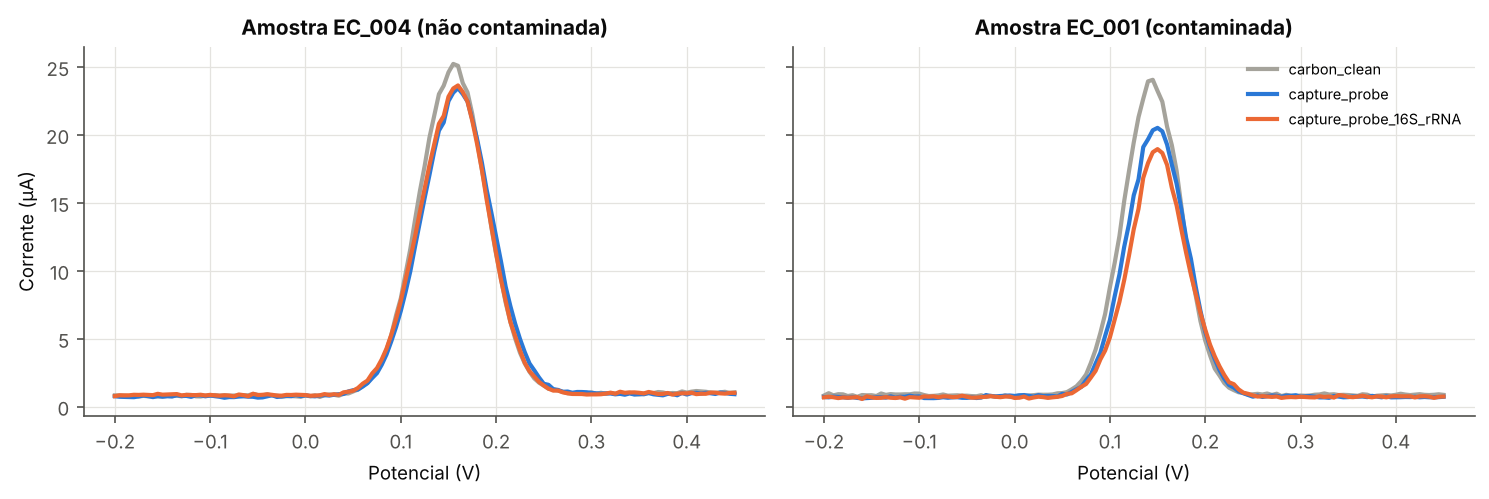

In [5]:
from fiep.preprocess import curvas_por_medicao, inferir_grade, para_matriz

ok = set(qc.loc[qc.qc_final == "PASS", "measurement_id"])
med = ds.medicoes[ds.medicoes.measurement_id.isin(ok)]
exemplo = {c: med[(med.contamination_status == c)].groupby(["sample_id", "replicate_id"]).filter(lambda g: len(g) == 3)
           .head(3) for c in (0, 1)}
estagios = cfg["dados"]["estagios"]
cores = {e: c for e, c in zip(estagios, ["#a5a39b", "#2a78d6", "#eb6834"])}

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, c in zip(axes, (0, 1)):
    for _, r in exemplo[c].iterrows():
        p = ds.pontos[ds.pontos.measurement_id == r.measurement_id].sort_values("potential_v")
        ax.plot(p.potential_v, p.current_ua, color=cores[r.sensor_state], label=r.sensor_state)
    ax.set_title(f"Amostra {exemplo[c].sample_id.iloc[0]} ({NOME_CLASSE[c]})")
    ax.set_xlabel("Potencial (V)")
axes[0].set_ylabel("Corrente (µA)")
axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

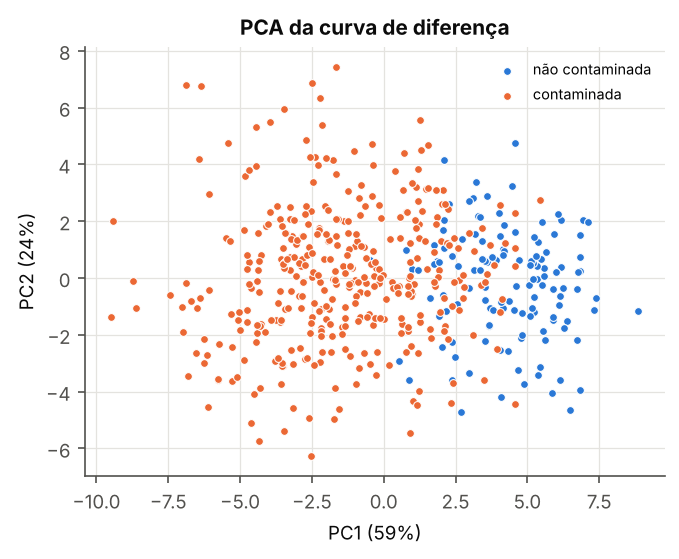

In [6]:
# PCA da curva de diferença (último − penúltimo estágio): as classes se separam?
from sklearn.decomposition import PCA
from fiep.features import tabela_features

curvas = curvas_por_medicao(ds.pontos, ok, cfg)
matriz = para_matriz(curvas, inferir_grade(curvas, cfg), cfg)
tab = tabela_features(matriz, ds.medicoes, cfg).dropna(subset=["contamination_status"])
D = tab[[c for c in tab.columns if c.startswith("D_")]].fillna(0)
pcs = PCA(n_components=2).fit(D)
z = pcs.transform(D)

fig, ax = plt.subplots(figsize=(4.6, 3.8))
for c in (0, 1):
    m = tab.contamination_status.to_numpy() == c
    ax.scatter(z[m, 0], z[m, 1], s=14, color=CLASSE[c], edgecolor="white", linewidth=0.5, label=NOME_CLASSE[c])
ax.set_xlabel(f"PC1 ({pcs.explained_variance_ratio_[0]:.0%})"); ax.set_ylabel(f"PC2 ({pcs.explained_variance_ratio_[1]:.0%})")
ax.set_title("PCA da curva de diferença"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 4. Experimentos: representações × modelos

`fiep.experimentos.rodar` aplica o protocolo descrito no artigo:

1. separa o **teste antes de tudo** (`dados/validacao/` ou 20% das amostras, estratificado);
2. avalia cada combinação de representação e modelo por **validação cruzada agrupada por amostra** só no treino;
3. escolhe a melhor pela validação cruzada (não pelo teste) e só então mede no teste;
4. ajusta a regressão da carga (log10 UFC/mL) nas contaminadas;
5. registra o modelo escolhido em `modelos/` (é o que a API usa) e gera figuras e tabelas para o artigo.

O experimento completo leva alguns minutos.

In [7]:
from fiep.experimentos import rodar, ultimo_experimento, DESCRICAO_VARIANTES

ds_val = ingerir(PASTA_VALIDACAO) if PASTA_VALIDACAO else None
# reaproveita o último experimento feito com exatamente estes dados (rode de novo com REFAZER = True)
REFAZER = False
r = None if REFAZER or ds_val is not None else ultimo_experimento(ds, "resultados")
if r is None:
    r = rodar(ds, cfg, ds_val, saida="resultados", pasta_modelos="modelos", rapido=RAPIDO)
else:
    print("Reaproveitando o experimento já rodado com estes dados (REFAZER = True para rodar de novo).")
pasta_exp = r["pasta"]
print("Experimento:", pasta_exp, "| teste:", r["resumo"]["teste"])
display(pd.Series(DESCRICAO_VARIANTES, name="descrição").to_frame())
r["placar"][["posicao", "variante", "modelo", "cv_balanced_accuracy", "cv_ba_desvio", "cv_roc_auc",
             "teste_balanced_accuracy", "teste_sensibilidade", "teste_especificidade", "teste_roc_auc"]].head(15).round(3)

Reaproveitando o experimento já rodado com estes dados (REFAZER = True para rodar de novo).
Experimento: resultados/20261020-121224 | teste: 20% das amostras separadas antes do treino (estratificado)


,descrição
dif_resumo,descritores de pico por estágio + diferenças e...
dif_curva,idem + curva de diferença completa (último − p...
dif_curva_linha_base,dif_curva com linha de base linear removida
dif_curva_sem_suavizar,dif_curva sem suavização Savitzky-Golay
estagio_final,só o estágio final do sensor (sem diferença en...


,posicao,variante,modelo,cv_balanced_accuracy,cv_ba_desvio,cv_roc_auc,teste_balanced_accuracy,teste_sensibilidade,teste_especificidade,teste_roc_auc
0,1,dif_curva_linha_base,log_reg_l1,0.948,0.022,0.977,0.946,0.934,0.958,0.983
1,2,dif_curva_sem_suavizar,log_reg_l1,0.946,0.038,0.976,0.932,0.947,0.917,0.976
2,3,dif_curva,log_reg_l1,0.941,0.033,0.976,0.911,0.947,0.875,0.982
3,4,dif_curva_linha_base,log_reg_C0.1,0.938,0.034,0.973,0.953,0.947,0.958,0.979
4,5,dif_curva_linha_base,log_reg,0.936,0.025,0.976,0.953,0.947,0.958,0.976
5,6,dif_curva_linha_base,log_reg_C0.01,0.935,0.037,0.967,0.953,0.947,0.958,0.985
6,7,dif_curva,log_reg,0.934,0.052,0.977,0.919,0.921,0.917,0.974
7,8,dif_curva_sem_suavizar,log_reg_C0.01,0.933,0.051,0.970,0.953,0.947,0.958,0.980
8,9,dif_curva,log_reg_C0.1,0.932,0.043,0.972,0.946,0.934,0.958,0.977
9,10,dif_curva,lda,0.930,0.020,0.976,0.953,0.947,0.958,0.965


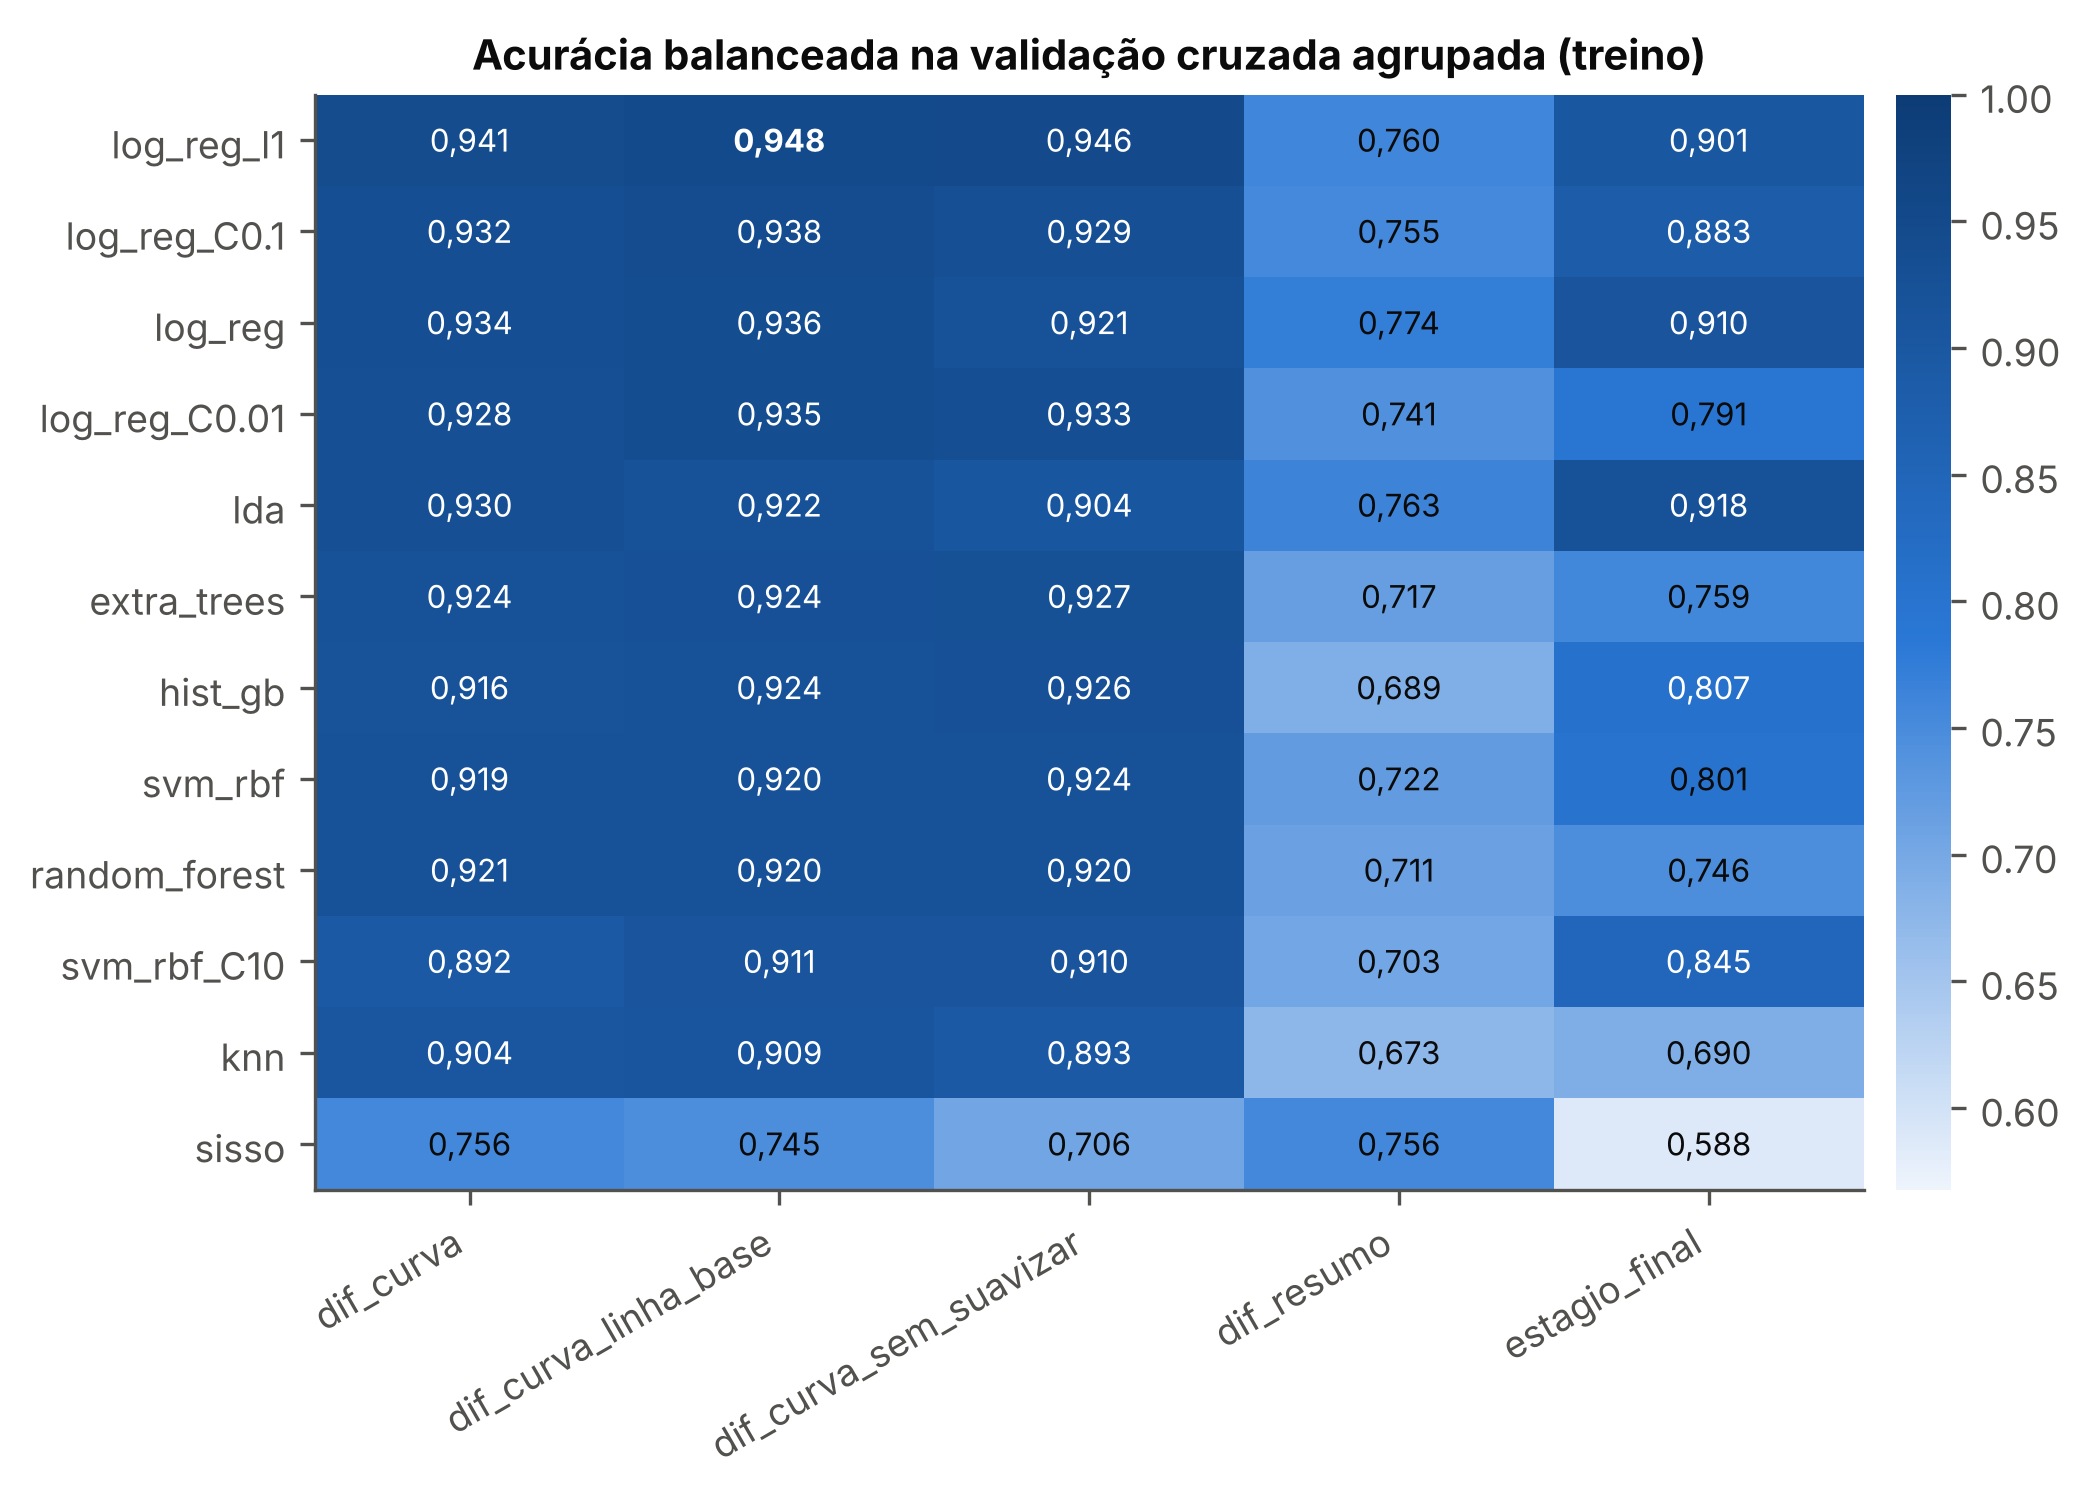

In [8]:
display(Image(pasta_exp / "figuras" / "comparacao_modelos.png", width=780))

## 5. Modelo escolhido

O desempenho de referência é o do **conjunto de teste**: a acurácia da melhor combinação na
validação cruzada tende a ser otimista, porque dezenas de combinações foram comparadas.

Escolhido: log_reg_l1 [dif_curva_linha_base] — dif_curva com linha de base linear removida
Validação cruzada: AB 0.948 ± 0.022 | AUC 0.977
Teste (40 amostras, 100 réplicas): AB 0.946 | sensibilidade 0.934 | especificidade 0.958 | AUC 0.983
Modelo registrado: modelos/20261020-122601


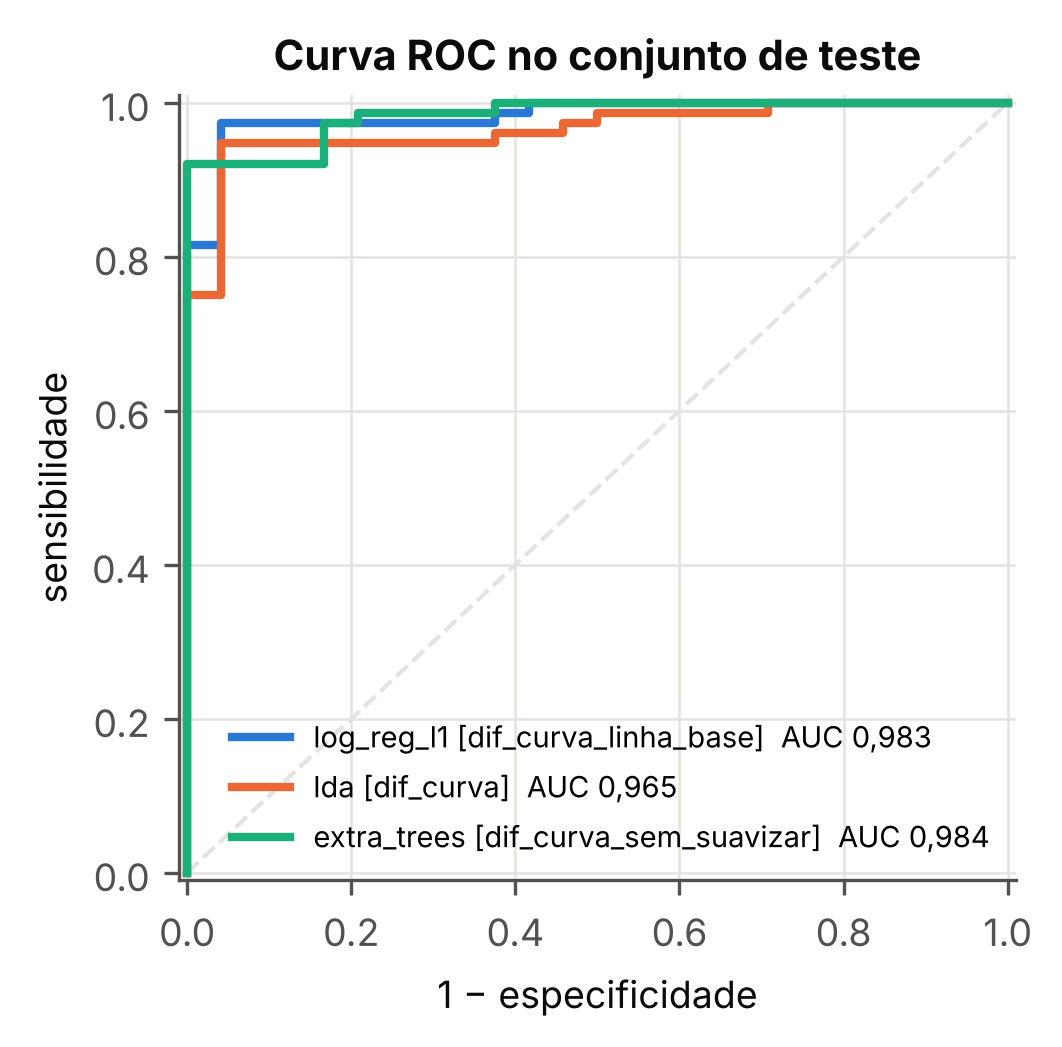

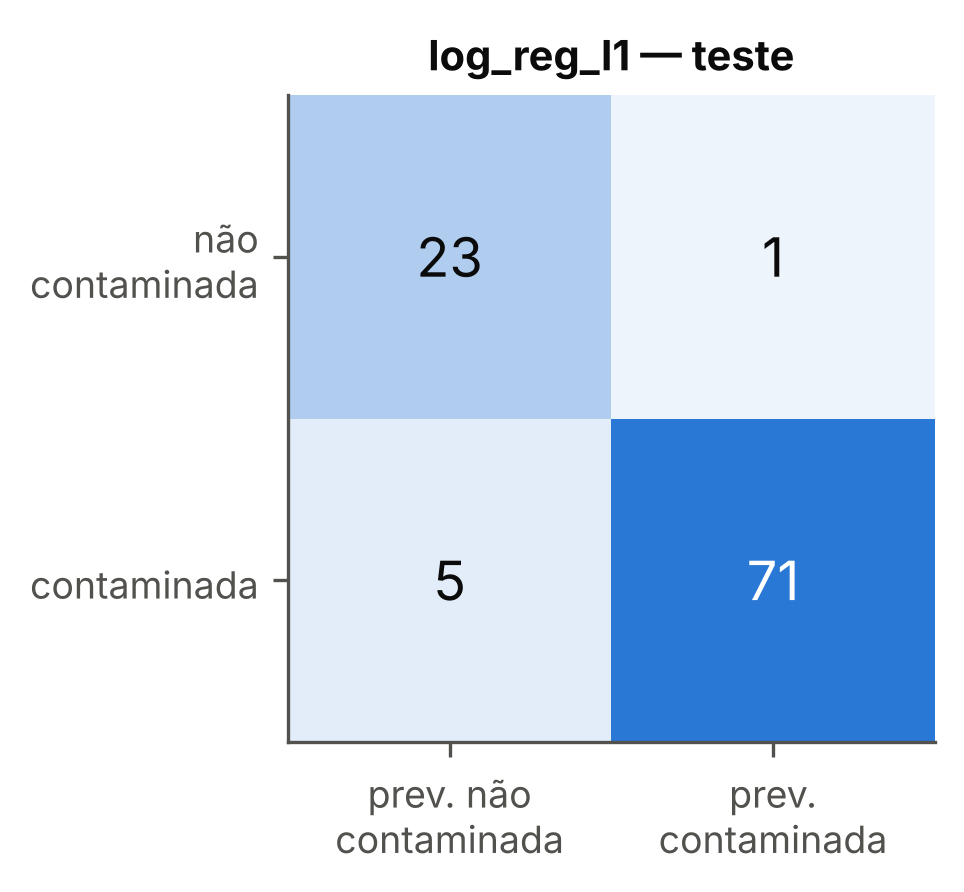

In [9]:
res = r["resumo"]; m = res["melhor"]
print(f"Escolhido: {m['modelo']} [{m['variante']}] — {res['descricao_variante']}")
print(f"Validação cruzada: AB {m['cv_balanced_accuracy']:.3f} ± {m['cv_ba_desvio']:.3f} | AUC {m['cv_roc_auc']:.3f}")
print(f"Teste ({res['amostras_teste']} amostras, {res['replicas_teste']} réplicas): AB {m['teste_balanced_accuracy']:.3f} | "
      f"sensibilidade {m['teste_sensibilidade']:.3f} | especificidade {m['teste_especificidade']:.3f} | AUC {m['teste_roc_auc']:.3f}")
print(f"Modelo registrado: modelos/{res.get('modelo_registrado')}")
for f in ["roc_teste.png", "matriz_confusao_teste.png"]:
    display(Image(pasta_exp / "figuras" / f, width=360))

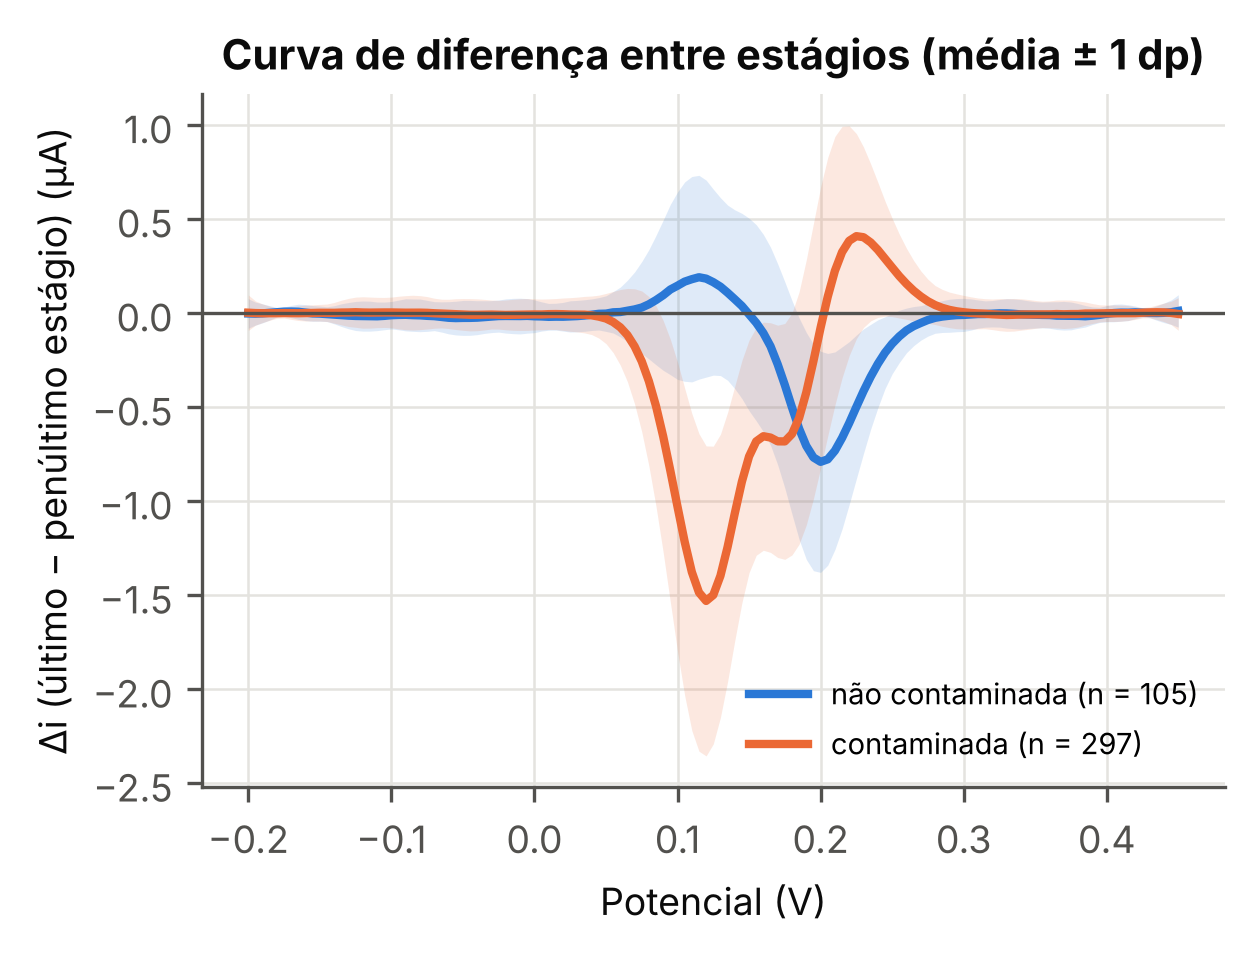

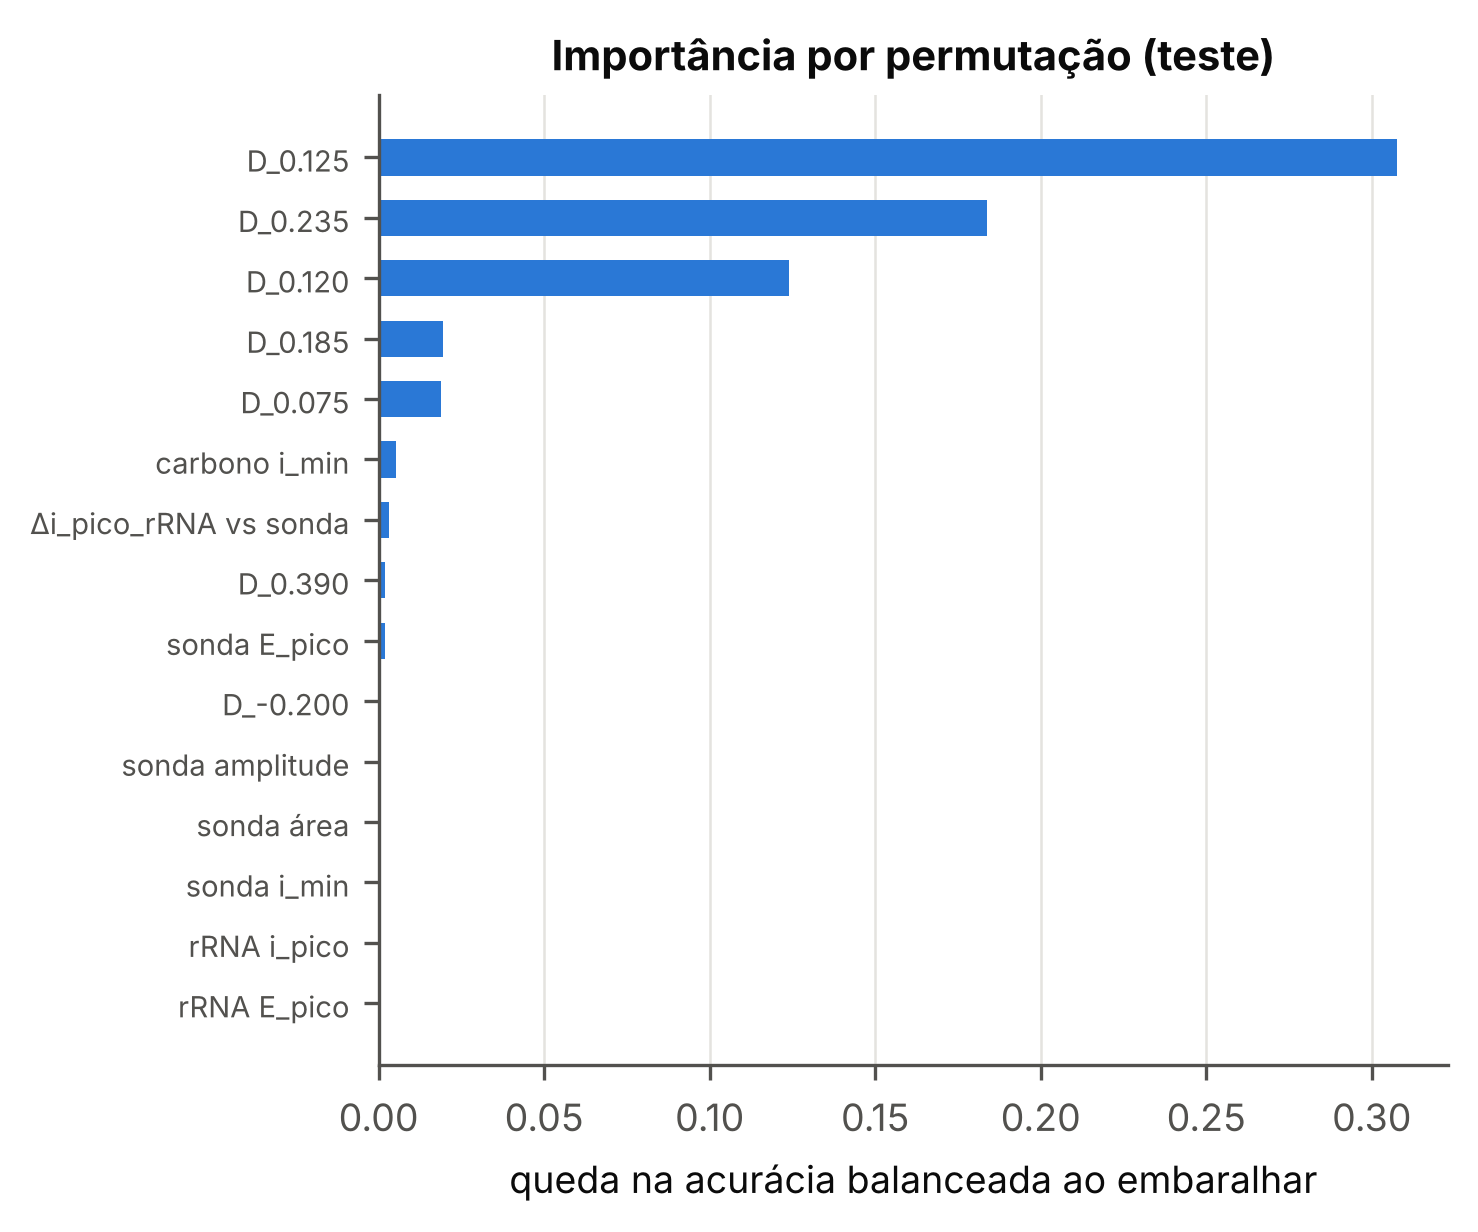

Descritor SISSO (interpretável):
  p(contaminada) = σ(-0.887·[(capture_probe_16S_rRNA_i_pico-capture_probe_i_pico)] -0.719·[(delta_area_capture_probe_16S_rRNA_vs_carbon_clean-delta_e_pico_capture_probe_16S_rRNA_vs_capture_probe)] +0.353)  (termos padronizados)


In [10]:
# O que o modelo usa: curva de diferença e importância por permutação no teste
for f in ["curvas_diferenca.png", "importancia.png"]:
    if (pasta_exp / "figuras" / f).exists():
        display(Image(pasta_exp / "figuras" / f, width=480))
print("Descritor SISSO (interpretável):\n ", res.get("formula_sisso"))

### Regressão da carga bacteriana

Nas amostras contaminadas, estima a carga em log10 UFC/mL a partir das mesmas características.
O regressor da mesma representação do classificador vai junto no modelo registrado, e a API
devolve a carga estimada quando a amostra é classificada como contaminada.

,variante,modelo,n_treino,cv_rmse,cv_mae,cv_r2,n_teste,teste_rmse,teste_mae,teste_r2
0,dif_curva_linha_base,ridge,297,0.790,0.630,0.725,76,0.808,0.669,0.655
1,dif_curva_linha_base,pls,297,0.823,0.655,0.701,76,0.861,0.682,0.609
2,dif_curva_linha_base,svr,297,0.925,0.749,0.623,76,0.923,0.722,0.550
3,dif_curva_linha_base,hist_gb,297,0.927,0.749,0.621,76,1.045,0.836,0.424
4,dif_curva_linha_base,extra_trees,297,0.978,0.798,0.578,76,1.050,0.856,0.418
5,dif_curva_linha_base,random_forest,297,1.008,0.832,0.552,76,1.101,0.902,0.360
6,dif_resumo,ridge,297,1.061,0.861,0.503,76,1.024,0.840,0.446
7,dif_resumo,pls,297,1.062,0.860,0.503,76,1.049,0.847,0.419
8,dif_resumo,extra_trees,297,1.130,0.926,0.437,76,1.200,0.968,0.240
9,dif_resumo,random_forest,297,1.153,0.945,0.414,76,1.296,1.030,0.113


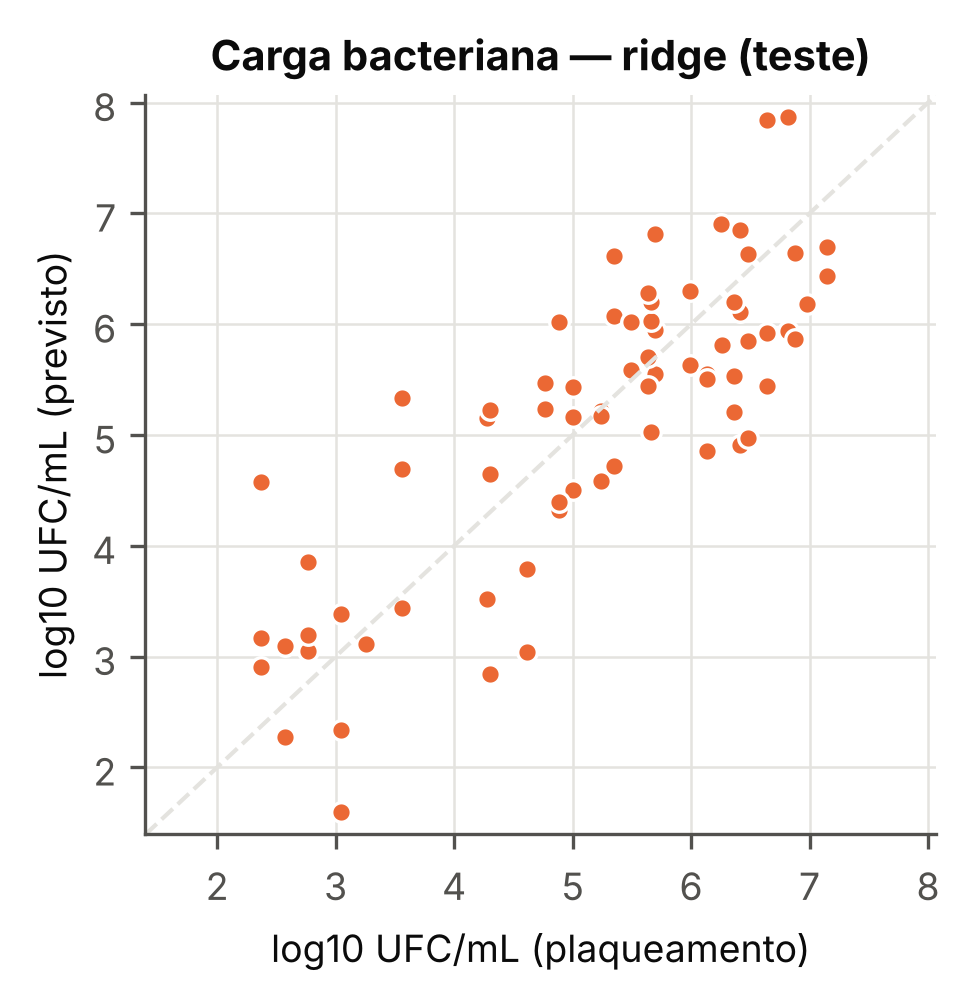

In [11]:
if len(r["regressao"]):
    display(r["regressao"].round(3))
    if (pasta_exp / "figuras" / "regressao_teste.png").exists():
        display(Image(pasta_exp / "figuras" / "regressao_teste.png", width=360))
else:
    print("Sem carga de referência (sample_log10_mean_cfu_ml) suficiente para a regressão.")

## 6. Previsão de uma coleta nova

É exatamente o que a página web (`fiep servir`) faz: lê os arquivos, aplica o controle de qualidade e o
pré-processamento **do modelo registrado** e devolve a classificação, a probabilidade e a carga estimada.
Aqui usamos as amostras de teste como se fossem uma coleta nova.

In [12]:
from fiep.model import carregar
from fiep.predict import prever
from fiep.experimentos import separar_teste, subconjunto

pacote = carregar("modelos")
if ds_val is not None:
    nova = ds_val
else:
    _, amostras_teste = separar_teste(ds, 0.2, cfg["modelo"]["seed"])
    nova = subconjunto(ds, amostras_teste)
saida = prever(nova, pacote)
db.gravar_predicoes(con, saida, pacote["cartao"], "modelos")
print(saida["resultado"].value_counts().to_string())
avaliadas = saida[saida.status == "avaliada"].dropna(subset=["rotulo_informado"])
if len(avaliadas):
    acerto = ((avaliadas.resultado == "CONTAMINADA").astype(int) == avaliadas.rotulo_informado).mean()
    print(f"\nAcerto nas réplicas avaliadas com rótulo: {acerto:.1%}")
saida.drop(columns=["measurement_id"]).head(12)

resultado
CONTAMINADA        72
NÃO CONTAMINADA    28
REPETIR MEDIÇÃO    22
SEM PREVISÃO       20

Acerto nas réplicas avaliadas com rótulo: 94.0%


,sample_id,replicate_id,status,prob_contaminada,resultado,confianca,log10_ufc_ml_estimado,cobertura_grade,motivo,rotulo_informado
0,EC_002,1,avaliada,0.9877,CONTAMINADA,0.9877,7.84,1.0,,1.0
1,EC_002,2,avaliada,0.9841,CONTAMINADA,0.9841,5.92,1.0,,1.0
2,EC_002,3,avaliada,0.9947,CONTAMINADA,0.9947,5.44,1.0,,1.0
3,EC_005,1,avaliada,0.9015,CONTAMINADA,0.9015,3.44,1.0,,1.0
4,EC_005,2,avaliada,0.7193,CONTAMINADA,0.7193,4.70,1.0,,1.0
5,EC_005,3,avaliada,0.9439,CONTAMINADA,0.9439,5.33,1.0,,1.0
6,EC_008,1,avaliada,0.9215,CONTAMINADA,0.9215,2.21,1.0,,0.0
7,EC_008,2,avaliada,0.1995,NÃO CONTAMINADA,0.8005,NaN,1.0,,0.0
8,EC_008,3,avaliada,0.0478,NÃO CONTAMINADA,0.9522,NaN,1.0,,0.0
9,EC_010,1,avaliada,1.0000,CONTAMINADA,1.0000,7.87,1.0,,1.0


## Conclusões e próximos passos

- A representação pela **diferença entre estágios** do mesmo eletrodo é a que separa as classes; o estágio
  final isolado e os descritores resumidos rendem bem menos. O protocolo de coleta precisa garantir os
  três estágios por eletrodo.
- O **controle de qualidade** automático impede que medições com sobrecarga ou potencial fora do aplicado
  entrem no treino.
- O modelo escolhido está registrado em `modelos/` e é usado pela página web (`fiep servir`);
  as figuras e tabelas deste experimento alimentam o artigo (`fiep experimento --artigo`).
- Próximo passo: substituir o conjunto de demonstração pelos dados reais em `dados/treino/` e uma coleta
  independente em `dados/validacao/` (validação externa, objetivo 7).

In [13]:
con.close()